# Credit Card Default Prediction

UCI Default of Credit Card Clients dataset (30,000 customers, Taiwan, 2005).

Reusable logic lives in `src/`. This notebook runs the pipeline and inspects results.


## Dataset Loading


In [1]:
import sys
import time
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Image, Markdown, display

from src.data_cleaning import (
    EDUCATION_LABELS,
    MARRIAGE_LABELS,
    SEX_LABELS,
    clean_dataset,
    count_unexpected_codes,
    data_quality_report,
)
from src.data_loader import TARGET_COLUMN, load_raw_dataset
from src.evaluation import compute_metrics, positive_class_probabilities
from src.fairness import add_age_group
from src.feature_engineering import ENGINEERED_FEATURES, engineer_features
from src.predict import load_model_artifact, predict_customers
from src.preprocessing import (
    RANDOM_STATE,
    build_model_pipeline,
    build_preprocessor,
    get_feature_lists,
    split_dataset,
)
from src.train import run_training_pipeline

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

IMAGES_DIR = PROJECT_ROOT / "images"
IMAGES_DIR.mkdir(parents=True, exist_ok=True)
print(f"Project root: {PROJECT_ROOT.name} | Random state: {RANDOM_STATE}")

Project root: default+of+credit+card+clients | Random state: 42


In [2]:
raw_df = load_raw_dataset()
print(f"Rows: {raw_df.shape[0]:,} | Columns: {raw_df.shape[1]}")
display(raw_df.head(3))

Rows: 30,000 | Columns: 25


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0


## 4. Data Understanding

One ID column, 23 features, and the binary target `default`.


In [3]:
schema = pd.DataFrame(
    {
        "dtype": raw_df.dtypes.astype(str),
        "non_null": raw_df.notna().sum(),
        "n_unique": raw_df.nunique(),
    }
)
display(schema)
display(
    raw_df[["LIMIT_BAL", "AGE", "PAY_1", "BILL_AMT1", "PAY_AMT1", TARGET_COLUMN]]
    .describe()
    .T.round(2)
)

,dtype,non_null,n_unique
ID,int64,30000,30000
LIMIT_BAL,int64,30000,81
SEX,int64,30000,2
EDUCATION,int64,30000,7
MARRIAGE,int64,30000,4
AGE,int64,30000,56
PAY_1,int64,30000,11
PAY_2,int64,30000,11
PAY_3,int64,30000,11
PAY_4,int64,30000,11


,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.32,129747.66,10000.0,50000.00,140000.0,240000.0,1000000.0
AGE,30000.0,35.49,9.22,21.0,28.00,34.0,41.0,79.0
PAY_1,30000.0,-0.02,1.12,-2.0,-1.00,0.0,0.0,8.0
BILL_AMT1,30000.0,51223.33,73635.86,-165580.0,3558.75,22381.5,67091.0,964511.0
PAY_AMT1,30000.0,5663.58,16563.28,0.0,1000.00,2100.0,5006.0,873552.0
default,30000.0,0.22,0.42,0.0,0.00,0.0,0.0,1.0


## 5. Data Quality Assessment

Missing values, duplicates, class balance, and unexpected category codes.


In [4]:
quality = data_quality_report(raw_df)
summary = pd.Series(
    {
        "Rows": quality["n_rows"],
        "Columns": quality["n_columns"],
        "Missing values": quality["missing_total"],
        "Duplicate rows": quality["duplicate_rows"],
        "Duplicate customer IDs": quality["duplicate_ids"],
        "Non-defaults (0)": quality["target_distribution"]["0"],
        "Defaults (1)": quality["target_distribution"]["1"],
        "Default rate": f"{quality['default_rate']:.2%}",
        "Imbalance ratio": f"{quality['imbalance_ratio']:.2f} : 1",
    }
)
display(summary.to_frame("value"))

unexpected = count_unexpected_codes(raw_df)
rows = [
    {"column": column, "code": code, "count": count}
    for column, counts in unexpected.items()
    for code, count in counts.items()
]
display(pd.DataFrame(rows).sort_values(["column", "code"]).reset_index(drop=True))

,value
Rows,30000
Columns,25
Missing values,0
Duplicate rows,0
Duplicate customer IDs,0
Non-defaults (0),23364
Defaults (1),6636
Default rate,22.12%
Imbalance ratio,3.52 : 1


,column,code,count
0,EDUCATION,0,14
1,EDUCATION,5,280
2,EDUCATION,6,51
3,MARRIAGE,0,54


In [5]:
display(
    Markdown(
        f"**Interpretation.** The data has **{quality['n_rows']:,} rows** and "
        f"**{quality['n_columns']} columns**. There are **{quality['missing_total']} missing values**, "
        f"**{quality['duplicate_rows']} duplicate rows**, and **{quality['duplicate_ids']} duplicate customer IDs**. "
        f"Defaults account for **{quality['default_rate']:.2%}** of records, so the majority class is about "
        f"**{quality['imbalance_ratio']:.1f}×** larger. Accuracy alone would be misleading.\n\n"
        "The undocumented `EDUCATION` codes 0, 5, and 6 and the `MARRIAGE` code 0 are present. "
        "They will be mapped to an explicit *others/unknown* category instead of being dropped, so no customer is "
        "silently removed."
    )
)

**Interpretation.** The data has **30,000 rows** and **25 columns**. There are **0 missing values**, **0 duplicate rows**, and **0 duplicate customer IDs**. Defaults account for **22.12%** of records, so the majority class is about **3.5×** larger. Accuracy alone would be misleading.

The undocumented `EDUCATION` codes 0, 5, and 6 and the `MARRIAGE` code 0 are present. They will be mapped to an explicit *others/unknown* category instead of being dropped, so no customer is silently removed.

## 6. Exploratory Data Analysis


In [6]:
counts = raw_df[TARGET_COLUMN].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(
    ["No default (0)", "Default (1)"],
    counts.values,
    color=["#457b9d", "#e76f51"],
)
for bar, value in zip(bars, counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + len(raw_df) * 0.005,
        f"{value:,}\n({value / len(raw_df):.1%})",
        ha="center",
        va="bottom",
    )
ax.set_title("Class distribution of next-month default")
ax.set_xlabel("Outcome")
ax.set_ylabel("Number of customers")
ax.set_ylim(0, counts.max() * 1.18)
plt.tight_layout()
plt.savefig(IMAGES_DIR / "01_target_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

display(
    Markdown(
        f"The positive class represents **{counts.loc[1] / len(raw_df):.2%}** of customers. "
        "This is a moderate imbalance: a majority-class classifier would look accurate but would have zero recall. "
        "PR-AUC and recall are therefore central to model selection."
    )
)

C:\Users\Ayat Ali\AppData\Local\Temp\ipykernel_20660\2836514209.py:22: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


The positive class represents **22.12%** of customers. This is a moderate imbalance: a majority-class classifier would look accurate but would have zero recall. PR-AUC and recall are therefore central to model selection.

### 6.2 Numerical distributions


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(
    data=raw_df,
    x="LIMIT_BAL",
    hue=TARGET_COLUMN,
    bins=40,
    stat="density",
    common_norm=False,
    element="step",
    ax=axes[0],
)
axes[0].set_title("Credit limit distribution by outcome")
axes[0].set_xlabel("Credit limit (NT$)")
axes[0].set_ylabel("Density")

sns.histplot(
    data=raw_df,
    x="AGE",
    hue=TARGET_COLUMN,
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    ax=axes[1],
)
axes[1].set_title("Age distribution by outcome")
axes[1].set_xlabel("Age (years)")
axes[1].set_ylabel("Density")

fig.suptitle("Customer profile distributions (source data)", y=1.02, fontsize=14)
plt.tight_layout()
plt.savefig(IMAGES_DIR / "02_credit_limit_and_age.png", dpi=150, bbox_inches="tight")
plt.show()

C:\Users\Ayat Ali\AppData\Local\Temp\ipykernel_20660\4291091593.py:33: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [8]:
bill_cap = raw_df["BILL_AMT1"].quantile(0.99)
payment_cap = raw_df["PAY_AMT1"].quantile(0.99)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(
    data=raw_df[raw_df["BILL_AMT1"] <= bill_cap],
    x="BILL_AMT1",
    hue=TARGET_COLUMN,
    bins=40,
    stat="density",
    common_norm=False,
    element="step",
    ax=axes[0],
)
axes[0].set_title("Most recent bill amount by outcome")
axes[0].set_xlabel("Bill amount in month 1 (NT$)")
axes[0].set_ylabel("Density")

sns.histplot(
    data=raw_df[raw_df["PAY_AMT1"] <= payment_cap],
    x="PAY_AMT1",
    hue=TARGET_COLUMN,
    bins=40,
    stat="density",
    common_norm=False,
    element="step",
    ax=axes[1],
)
axes[1].set_title("Most recent payment amount by outcome")
axes[1].set_xlabel("Payment amount in month 1 (NT$)")
axes[1].set_ylabel("Density")

fig.suptitle(
    "Bill and payment distributions (99th percentile clipped for readability only)",
    y=1.02,
    fontsize=14,
)
plt.tight_layout()
plt.savefig(IMAGES_DIR / "03_bill_and_payment.png", dpi=150, bbox_inches="tight")
plt.show()

display(
    Markdown(
        "Both financial variables are heavily right-skewed. The clip at the 99th percentile is a visualisation aid "
        "only; the extreme observations are retained for modelling because high-value customers are legitimate. "
        "The outcome groups overlap substantially, which is expected: single variables are weak predictors on their own."
    )
)

C:\Users\Ayat Ali\AppData\Local\Temp\ipykernel_20660\2151272486.py:40: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Both financial variables are heavily right-skewed. The clip at the 99th percentile is a visualisation aid only; the extreme observations are retained for modelling because high-value customers are legitimate. The outcome groups overlap substantially, which is expected: single variables are weak predictors on their own.

### 6.3 Categorical analysis

Default rates by education, marriage, sex, and age group.


In [9]:
def annotate_rates(ax, values):
    for patch, value in zip(ax.patches, values):
        ax.text(
            patch.get_x() + patch.get_width() / 2,
            patch.get_height() + 0.005,
            f"{value:.1%}",
            ha="center",
            va="bottom",
            fontsize=8,
        )


fig, axes = plt.subplots(2, 2, figsize=(14, 9))

edu_summary = raw_df.groupby("EDUCATION")[TARGET_COLUMN].agg(["count", "mean"]).sort_index()
axes[0, 0].bar(
    range(len(edu_summary)),
    edu_summary["mean"],
    color="#2a6f97",
)
axes[0, 0].set_xticks(
    range(len(edu_summary)),
    [EDUCATION_LABELS.get(int(code), f"code {int(code)}") for code in edu_summary.index],
    rotation=25,
    ha="right",
)
axes[0, 0].set_title("Default rate by education")
axes[0, 0].set_ylabel("Default rate")
annotate_rates(axes[0, 0], edu_summary["mean"])

marriage_summary = raw_df.groupby("MARRIAGE")[TARGET_COLUMN].agg(["count", "mean"]).sort_index()
axes[0, 1].bar(
    range(len(marriage_summary)),
    marriage_summary["mean"],
    color="#2a6f97",
)
axes[0, 1].set_xticks(
    range(len(marriage_summary)),
    [MARRIAGE_LABELS.get(int(code), f"code {int(code)}") for code in marriage_summary.index],
    rotation=25,
    ha="right",
)
axes[0, 1].set_title("Default rate by marriage status")
axes[0, 1].set_ylabel("Default rate")
annotate_rates(axes[0, 1], marriage_summary["mean"])

sex_summary = raw_df.groupby("SEX")[TARGET_COLUMN].agg(["count", "mean"]).sort_index()
axes[1, 0].bar(
    [SEX_LABELS.get(int(code), str(code)) for code in sex_summary.index],
    sex_summary["mean"],
    color="#2a6f97",
)
axes[1, 0].set_title("Default rate by sex")
axes[1, 0].set_ylabel("Default rate")
annotate_rates(axes[1, 0], sex_summary["mean"])

age_summary = (
    add_age_group(raw_df)
    .groupby("AGE_GROUP", observed=True)[TARGET_COLUMN]
    .agg(["count", "mean"])
)
axes[1, 1].bar(age_summary.index.astype(str), age_summary["mean"], color="#2a6f97")
axes[1, 1].set_title("Default rate by age group")
axes[1, 1].set_xlabel("Age group")
axes[1, 1].set_ylabel("Default rate")
annotate_rates(axes[1, 1], age_summary["mean"])

fig.suptitle("Default rates across demographic groups (source data)", y=1.00, fontsize=14)
plt.tight_layout()
plt.savefig(IMAGES_DIR / "04_default_rate_by_demographics.png", dpi=150, bbox_inches="tight")
plt.show()

C:\Users\Ayat Ali\AppData\Local\Temp\ipykernel_20660\4019938546.py:71: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [10]:
highest_edu = edu_summary["mean"].idxmax()
highest_age = age_summary["mean"].idxmax()
display(
    Markdown(
        "**Interpretation.** Default rates differ across groups. In this sample, education level "
        f"**{EDUCATION_LABELS.get(int(highest_edu), f'code {int(highest_edu)}')}** has the highest observed rate, "
        f"and the **{highest_age}** age group has the highest rate. These are descriptive associations, not causal "
        "effects. Group labels with very small counts should be interpreted cautiously, and preprocessing will "
        "one-hot encode these categories."
    )
)

**Interpretation.** Default rates differ across groups. In this sample, education level **high school** has the highest observed rate, and the **60+** age group has the highest rate. These are descriptive associations, not causal effects. Group labels with very small counts should be interpreted cautiously, and preprocessing will one-hot encode these categories.

### 6.4 Correlation analysis


In [11]:
correlation_columns = [column for column in raw_df.columns if column not in {"ID", TARGET_COLUMN}]
corr = raw_df[correlation_columns + [TARGET_COLUMN]].corr(method="spearman")

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.3,
    ax=ax,
)
ax.set_title("Spearman correlation matrix (source data)")
plt.tight_layout()
plt.savefig(IMAGES_DIR / "05_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

target_corr = (
    corr[TARGET_COLUMN]
    .drop(TARGET_COLUMN)
    .sort_values(key=lambda values: values.abs(), ascending=False)
)
display(target_corr.head(10).to_frame("Spearman correlation with default").round(3))

C:\Users\Ayat Ali\AppData\Local\Temp\ipykernel_20660\1551343834.py:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


,Spearman correlation with default
PAY_1,0.292
PAY_2,0.217
PAY_3,0.195
PAY_4,0.174
LIMIT_BAL,-0.170
PAY_AMT1,-0.160
PAY_5,0.159
PAY_AMT2,-0.151
PAY_6,0.143
PAY_AMT3,-0.139


In [12]:
top_features = target_corr.head(3).index.tolist()
display(
    Markdown(
        "The strongest univariate rank associations with default are "
        + ", ".join(f"`{feature}`" for feature in top_features)
        + ". The repayment-status variables are correlated with each other and the bill variables are strongly "
        "correlated across months. Models can handle this redundancy, but coefficients should not be read as "
        "independent causal effects."
    )
)

The strongest univariate rank associations with default are `PAY_1`, `PAY_2`, `PAY_3`. The repayment-status variables are correlated with each other and the bill variables are strongly correlated across months. Models can handle this redundancy, but coefficients should not be read as independent causal effects.

### 6.5 Repayment history vs default

`PAY_1` is the most recent repayment status.


In [13]:
pay_summary = (
    raw_df.groupby("PAY_1")[TARGET_COLUMN]
    .agg(["count", "mean"])
    .reset_index()
    .rename(columns={"count": "customers", "mean": "default_rate"})
)
fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(pay_summary["PAY_1"].astype(str), pay_summary["default_rate"], color="#e76f51")
for bar, value in zip(bars, pay_summary["default_rate"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f"{value:.1%}",
        ha="center",
        va="bottom",
        fontsize=8,
    )
ax.set_title("Default rate by most recent repayment status (PAY_1)")
ax.set_xlabel("Repayment status (-2 = no card use, -1 = paid in full, 0 = revolving, 1+ = months delayed)")
ax.set_ylabel("Default rate")
ax.set_ylim(0, min(1.0, pay_summary["default_rate"].max() * 1.15))
plt.tight_layout()
plt.savefig(IMAGES_DIR / "06_repayment_status_vs_default.png", dpi=150, bbox_inches="tight")
plt.show()

display(pay_summary.round(4))

C:\Users\Ayat Ali\AppData\Local\Temp\ipykernel_20660\1629684637.py:24: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


,PAY_1,customers,default_rate
0,-2,2759,0.1323
1,-1,5686,0.1678
2,0,14737,0.1281
3,1,3688,0.3395
4,2,2667,0.6914
5,3,322,0.7578
6,4,76,0.6842
7,5,26,0.5000
8,6,11,0.5455
9,7,9,0.7778


In [14]:
delayed = pay_summary.loc[pay_summary["PAY_1"] >= 1]
current = pay_summary.loc[pay_summary["PAY_1"] <= 0]
delayed_rate = float(np.average(delayed["default_rate"], weights=delayed["customers"]))
current_rate = float(np.average(current["default_rate"], weights=current["customers"]))
display(
    Markdown(
        f"Customers with one or more months of delay in the most recent status default at a "
        f"record-weighted rate of **{delayed_rate:.1%}** across {int(delayed['customers'].sum()):,} customers, "
        f"versus **{current_rate:.1%}** for {int(current['customers'].sum()):,} customers who are current or have no usage. "
        "The relationship is monotonic for most statuses, which supports using repayment history and engineered "
        "delay-count features. Because this is observational data, the association is predictive rather than causal."
    )
)

Customers with one or more months of delay in the most recent status default at a record-weighted rate of **50.3%** across 6,818 customers, versus **13.8%** for 23,182 customers who are current or have no usage. The relationship is monotonic for most statuses, which supports using repayment history and engineered delay-count features. Because this is observational data, the association is predictive rather than causal.

## 7. Data Cleaning


In [15]:
education_before = raw_df["EDUCATION"].value_counts().sort_index()
marriage_before = raw_df["MARRIAGE"].value_counts().sort_index()

cleaned_df = clean_dataset(raw_df)

print(f"Rows before cleaning: {len(raw_df):,}")
print(f"Rows after cleaning:  {len(cleaned_df):,}")
print(f"Rows removed as exact duplicates: {len(raw_df) - len(cleaned_df):,}")

education_comparison = pd.DataFrame(
    {
        "before": education_before,
        "after": cleaned_df["EDUCATION"].value_counts().sort_index(),
    }
).fillna(0).astype(int)
marriage_comparison = pd.DataFrame(
    {
        "before": marriage_before,
        "after": cleaned_df["MARRIAGE"].value_counts().sort_index(),
    }
).fillna(0).astype(int)

print("\nEDUCATION codes before vs after")
display(education_comparison)
print("MARRIAGE codes before vs after")
display(marriage_comparison)

Rows before cleaning: 30,000
Rows after cleaning:  30,000
Rows removed as exact duplicates: 0

EDUCATION codes before vs after


,before,after
EDUCATION,,
0,14,0
1,10585,10585
2,14030,14030
3,4917,4917
4,123,468
5,280,0
6,51,0


MARRIAGE codes before vs after


,before,after
MARRIAGE,,
0,54,0
1,13659,13659
2,15964,15964
3,323,377


In [16]:
education_mapped = int(raw_df["EDUCATION"].isin([0, 5, 6]).sum())
marriage_mapped = int((raw_df["MARRIAGE"] == 0).sum())
display(
    Markdown(
        f"**{education_mapped:,}** education records and **{marriage_mapped:,}** marriage records used "
        "undocumented codes and were folded into the explicit *others/unknown* category. No rows were discarded "
        "for this reason, and the target distribution is unchanged. The original file in `data/raw/` is never "
        "modified."
    )
)

**345** education records and **54** marriage records used undocumented codes and were folded into the explicit *others/unknown* category. No rows were discarded for this reason, and the target distribution is unchanged. The original file in `data/raw/` is never modified.

## 8. Feature Engineering

Aggregates over the six billing months, utilisation ratios, and delay counts.


In [17]:
model_df = engineer_features(cleaned_df)

print(f"Columns after feature engineering: {model_df.shape[1]}")
print(f"Engineered features: {len(ENGINEERED_FEATURES)}")
print(
    "Infinite values after engineering:",
    int(np.isinf(model_df.select_dtypes(include=[np.number])).sum().sum()),
)
display(
    model_df[
        [
            "LIMIT_BAL",
            "BILL_AVG",
            "PAY_TOTAL",
            "NUM_DELAYED_MONTHS",
            "MAX_DELAY_STATUS",
            "UTILIZATION_AVG",
            "PAYMENT_TO_BILL_RATIO",
        ]
    ].head()
)
display(model_df[ENGINEERED_FEATURES].describe().T.round(2))

Columns after feature engineering: 37
Engineered features: 12
Infinite values after engineering: 0


,LIMIT_BAL,BILL_AVG,PAY_TOTAL,NUM_DELAYED_MONTHS,MAX_DELAY_STATUS,UTILIZATION_AVG,PAYMENT_TO_BILL_RATIO
0,20000,1284.000000,689.0,2.0,2.0,0.064200,0.089434
1,120000,2846.166667,5000.0,2.0,2.0,0.023718,0.292791
2,90000,16942.166667,11018.0,0.0,0.0,0.188246,0.108388
3,50000,38555.666667,8388.0,0.0,0.0,0.771113,0.036259
4,50000,18223.166667,59049.0,0.0,0.0,0.364463,0.540054


,count,mean,std,min,25%,50%,75%,max
BILL_AVG,30000.0,44976.95,63260.72,-56043.17,4781.33,21051.83,57104.42,877313.83
BILL_TOTAL,30000.0,269861.67,379564.33,-336259.00,28688.00,126311.00,342626.50,5263883.00
PAY_AVG,30000.0,5275.23,10137.95,0.00,1113.29,2397.17,5583.92,627344.33
PAY_TOTAL,30000.0,31651.39,60827.68,0.00,6679.75,14383.00,33503.50,3764066.00
NUM_DELAYED_MONTHS,30000.0,0.83,1.55,0.00,0.00,0.00,1.00,6.00
NUM_SEVERE_DELAY_MONTHS,30000.0,0.71,1.46,0.00,0.00,0.00,1.00,6.00
MAX_DELAY_STATUS,30000.0,0.44,1.35,-2.00,0.00,0.00,2.00,8.00
AVG_DELAY_STATUS,30000.0,-0.18,0.98,-2.00,-0.83,0.00,0.00,6.00
UTILIZATION_AVG,30000.0,0.37,0.35,-0.23,0.03,0.28,0.69,5.36
UTILIZATION_LAST,30000.0,0.42,0.41,-0.62,0.02,0.31,0.83,6.46


In [18]:
zero_limits = int((model_df["LIMIT_BAL"] == 0).sum())
display(
    Markdown(
        f"The engineered frame has **{model_df.shape[1]} columns** (23 original features plus 12 engineered features "
        f"plus the target). There are **{zero_limits}** zero credit limits in this dataset; the guarded division "
        "still guarantees finite utilisation features for any such record, which is covered by unit tests."
    )
)

The engineered frame has **37 columns** (23 original features plus 12 engineered features plus the target). There are **0** zero credit limits in this dataset; the guarded division still guarantees finite utilisation features for any such record, which is covered by unit tests.

## 9. Train / Validation / Test Split

Stratified 70/15/15, `random_state=42`. Split happens before any fitting.


In [19]:
train_df, validation_df, test_df = split_dataset(model_df)

split_rows = []
for name, split in [
    ("Train", train_df),
    ("Validation", validation_df),
    ("Test", test_df),
]:
    split_rows.append(
        {
            "split": name,
            "rows": len(split),
            "share": len(split) / len(model_df),
            "default_rate": split[TARGET_COLUMN].mean(),
        }
    )
split_summary = pd.DataFrame(split_rows)
display(split_summary.round(4))

id_overlap = (
    set(train_df["ID"]) & set(validation_df["ID"])
    | set(train_df["ID"]) & set(test_df["ID"])
    | set(validation_df["ID"]) & set(test_df["ID"])
)
print(f"Customer IDs shared across splits: {len(id_overlap)}")

,split,rows,share,default_rate
0,Train,21000,0.70,0.2212
1,Validation,4500,0.15,0.2211
2,Test,4500,0.15,0.2211


Customer IDs shared across splits: 0


In [20]:
display(
    Markdown(
        f"The training split has **{len(train_df):,}** customers, validation has **{len(validation_df):,}**, and "
        f"test has **{len(test_df):,}**. The default rate is preserved at approximately "
        f"**{train_df[TARGET_COLUMN].mean():.2%}**, **{validation_df[TARGET_COLUMN].mean():.2%}**, and "
        f"**{test_df[TARGET_COLUMN].mean():.2%}** respectively. No customer appears in more than one split."
    )
)

The training split has **21,000** customers, validation has **4,500**, and test has **4,500**. The default rate is preserved at approximately **22.12%**, **22.11%**, and **22.11%** respectively. No customer appears in more than one split.

## 10. Preprocessing

- Numeric: median impute → StandardScaler
- Categorical: most-frequent impute → OneHotEncoder
- All inside a sklearn Pipeline fitted on training data only


In [21]:
numeric_features, categorical_features = get_feature_lists(train_df)
feature_columns = [
    column for column in train_df.columns if column not in {"ID", TARGET_COLUMN}
]

X_train = train_df[feature_columns]
y_train = train_df[TARGET_COLUMN]
X_valid = validation_df[feature_columns]
y_valid = validation_df[TARGET_COLUMN]
X_test = test_df[feature_columns]
y_test = test_df[TARGET_COLUMN]

print(f"Numeric features: {len(numeric_features)}")
print(f"Categorical features: {categorical_features}")
print(f"Total model features: {len(feature_columns)}")

preprocessor = build_preprocessor(numeric_features, categorical_features)
preprocessor.fit(X_train)
transformed_train = preprocessor.transform(X_train)
transformed_valid = preprocessor.transform(X_valid)
transformed_test = preprocessor.transform(X_test)

print(f"Transformed training matrix: {transformed_train.shape}")
print(f"Transformed validation matrix: {transformed_valid.shape}")
print(f"Transformed test matrix: {transformed_test.shape}")

Numeric features: 32
Categorical features: ['SEX', 'EDUCATION', 'MARRIAGE']
Total model features: 35


Transformed training matrix: (21000, 41)
Transformed validation matrix: (4500, 41)
Transformed test matrix: (4500, 41)


In [22]:
imputer = preprocessor.named_transformers_["numeric"].named_steps["imputer"]
scaler = preprocessor.named_transformers_["numeric"].named_steps["scaler"]

leakage_check = pd.DataFrame(
    {
        "train_median": X_train[numeric_features].median().to_numpy(),
        "imputer_statistic": imputer.statistics_,
        "train_mean": X_train[numeric_features].mean().to_numpy(),
        "scaler_mean": scaler.mean_,
    },
    index=numeric_features,
).head(8)
display(leakage_check.round(4))

display(
    Markdown(
        "The imputer statistics and scaler means equal the training statistics, not statistics computed on the "
        "full dataset. This is the leakage guard required by the project: validation and test observations cannot "
        "influence learned preprocessing parameters."
    )
)

,train_median,imputer_statistic,train_mean,scaler_mean
LIMIT_BAL,140000.0,140000.0,166947.4286,166947.4286
AGE,34.0,34.0,35.3996,35.3996
PAY_1,0.0,0.0,-0.0069,-0.0069
PAY_2,0.0,0.0,-0.1256,-0.1256
PAY_3,0.0,0.0,-0.1610,-0.1610
PAY_4,0.0,0.0,-0.2190,-0.2190
PAY_5,0.0,0.0,-0.2670,-0.2670
PAY_6,0.0,0.0,-0.2885,-0.2885


The imputer statistics and scaler means equal the training statistics, not statistics computed on the full dataset. This is the leakage guard required by the project: validation and test observations cannot influence learned preprocessing parameters.

## 11. Baseline Model

DummyClassifier (majority class) as reference.


In [23]:
from sklearn.dummy import DummyClassifier

baseline = build_model_pipeline(
    DummyClassifier(strategy="prior", random_state=RANDOM_STATE),
    numeric_features,
    categorical_features,
)
baseline.fit(X_train, y_train)
baseline_probabilities = positive_class_probabilities(baseline, X_valid)
baseline_metrics = compute_metrics(y_valid, baseline_probabilities, threshold=0.5)

baseline_view = pd.Series(
    {
        key: baseline_metrics[key]
        for key in ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]
    }
)
display(baseline_view.to_frame("majority-class baseline").round(4))
display(
    Markdown(
        f"The baseline reaches **{baseline_metrics['accuracy']:.2%} accuracy** by predicting no defaults at the "
        f"0.50 threshold, but it has **{baseline_metrics['recall']:.0%} recall** and "
        f"**{baseline_metrics['f1']:.3f} F1**. Its PR-AUC of **{baseline_metrics['pr_auc']:.3f}** is close to the "
        f"positive prevalence ({y_valid.mean():.1%}), the value expected from a model with no ranking power. "
        "This confirms that model comparison must prioritise recall, F1, and PR-AUC."
    )
)

,majority-class baseline
accuracy,0.7789
precision,0.0000
recall,0.0000
f1,0.0000
roc_auc,0.5000
pr_auc,0.2211


The baseline reaches **77.89% accuracy** by predicting no defaults at the 0.50 threshold, but it has **0% recall** and **0.000 F1**. Its PR-AUC of **0.221** is close to the positive prevalence (22.1%), the value expected from a model with no ranking power. This confirms that model comparison must prioritise recall, F1, and PR-AUC.

## 12. Model Training


In [24]:
start = time.perf_counter()
results = run_training_pipeline(
    random_state=RANDOM_STATE,
    cv_folds=5,
    tune=True,
    run_imbalance_experiments=True,
)
elapsed = time.perf_counter() - start
print(f"\nFull pipeline wall time: {elapsed / 60:.1f} minutes")

Loading dataset: default of credit card clients.xls


Rows: 30,000 | Raw columns: 25 | Modelled columns: 37
Split sizes -> train: 21,000 | validation: 4,500 | test: 4,500
Training base models...


  Logistic Regression: PR-AUC=0.5487 | ROC-AUC=0.7711 | F1=0.4190


  Decision Tree: PR-AUC=0.5331 | ROC-AUC=0.7707 | F1=0.4668


  Random Forest: PR-AUC=0.5703 | ROC-AUC=0.7856 | F1=0.4771


  K-Nearest Neighbors: PR-AUC=0.5235 | ROC-AUC=0.7609 | F1=0.4440


... (7 outputs left out)

Selected threshold on training out-of-fold data: 0.50 (diagnostic validation-only F1 threshold: 0.50)
Refitting selected pipeline on train + validation...


Evaluating once on the untouched test set...
Computing permutation importance on the validation split...


Running exploratory subgroup analysis on the test set...


Final test metrics (selected threshold):
  accuracy: 0.7949
  precision: 0.5348
  recall: 0.5558
  f1: 0.5451
  roc_auc: 0.7802
  pr_auc: 0.5598
Pipeline completed in 397.2s

Full pipeline wall time: 6.6 minutes


## 13. Model Comparison

Same preprocessing and validation split for all models.


,selection_rank,model,role,eligible,validation_accuracy,validation_precision,validation_recall,validation_f1,validation_roc_auc,validation_pr_auc,cv_pr_auc_mean,fit_time_seconds
0,1,Random Forest (class weights),imbalance,True,0.8024,0.5528,0.5578,0.5553,0.7845,0.5623,NaN,2.709
1,2,Gradient Boosting (tuned),tuned,False,0.8284,0.7271,0.3588,0.4805,0.7918,0.5713,0.5532,172.023
2,3,Gradient Boosting,base,False,0.8284,0.7243,0.3618,0.4826,0.7920,0.5709,0.5556,20.353
3,4,Random Forest,base,False,0.8276,0.7239,0.3558,0.4771,0.7856,0.5703,0.5567,2.068
4,5,Random Forest (tuned),tuned,False,0.8264,0.7131,0.3598,0.4783,0.7834,0.5665,0.5546,43.741
5,6,Logistic Regression + SMOTE,imbalance,False,0.7544,0.4590,0.6191,0.5272,0.7708,0.5498,NaN,0.241
6,7,Support Vector Machine,base,False,0.8187,0.7157,0.2985,0.4213,0.7695,0.5491,0.5249,0.365
7,8,Logistic Regression,base,False,0.8176,0.7081,0.2975,0.4190,0.7711,0.5487,0.5237,0.146
8,9,Logistic Regression (class weights),imbalance,False,0.7558,0.4613,0.6231,0.5301,0.7713,0.5479,NaN,0.131
9,10,Decision Tree,base,False,0.8253,0.7182,0.3457,0.4668,0.7707,0.5331,0.5258,0.350


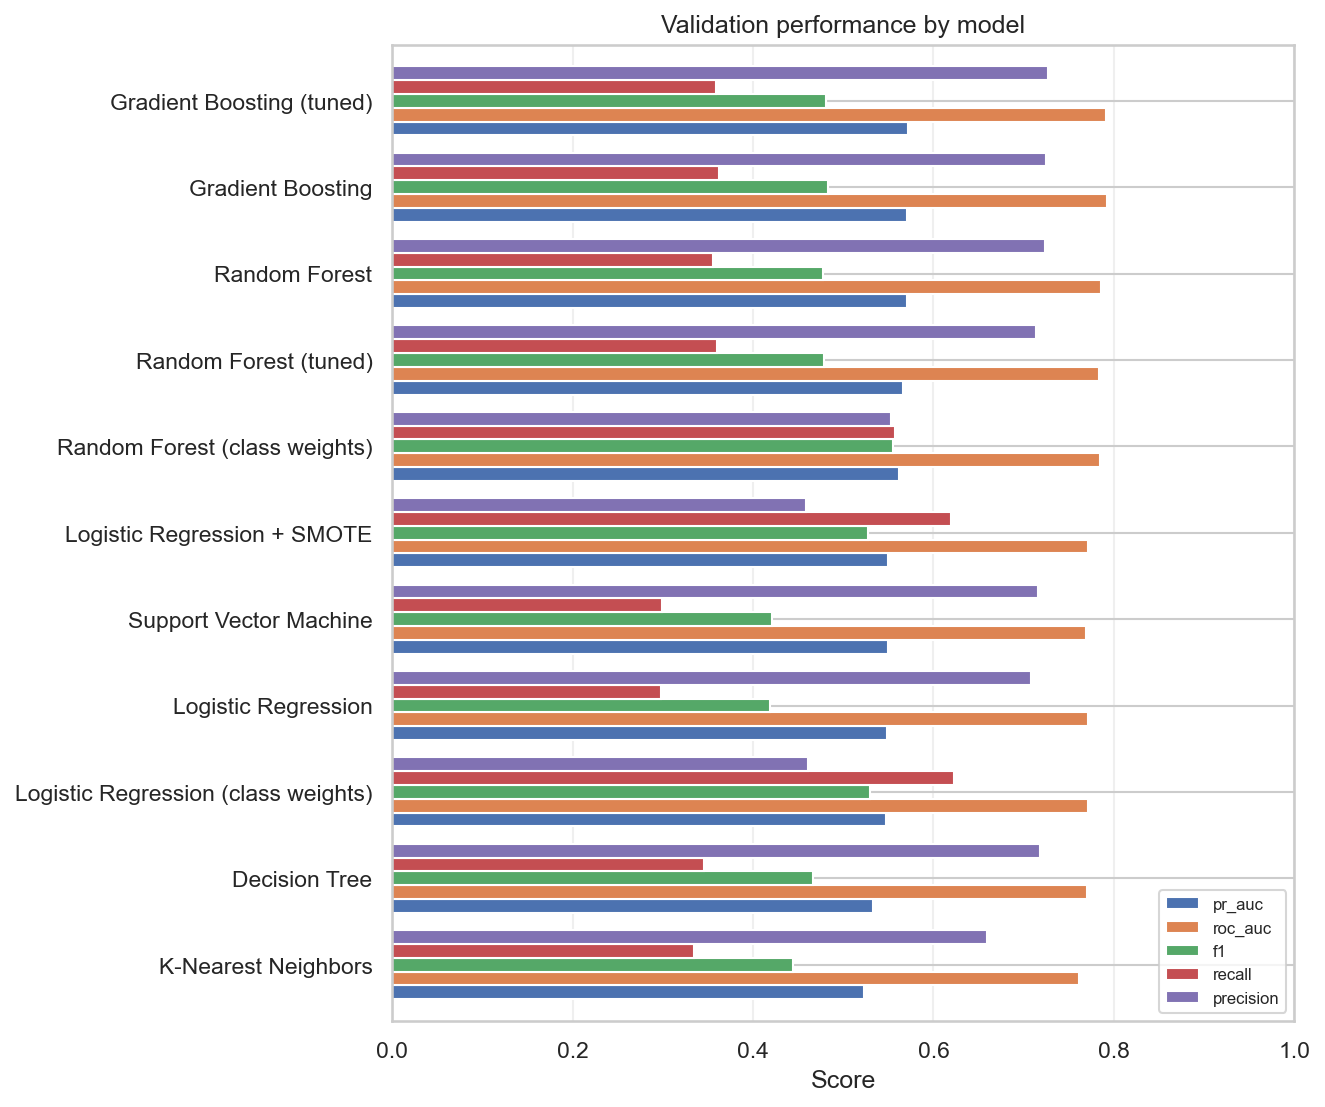

In [25]:
comparison = results["comparison"].copy()
display_columns = [
    "selection_rank",
    "model",
    "role",
    "eligible",
    "validation_accuracy",
    "validation_precision",
    "validation_recall",
    "validation_f1",
    "validation_roc_auc",
    "validation_pr_auc",
    "cv_pr_auc_mean",
    "fit_time_seconds",
]
display(
    comparison.sort_values("selection_rank")[display_columns]
    .round(4)
    .reset_index(drop=True)
)

display(Image(filename=str(PROJECT_ROOT / "images" / "07_model_comparison.png")))


ROC and PR curves for the base models on the validation set.


In [26]:
base_results = comparison[comparison["role"] == "base"].sort_values(
    "validation_pr_auc", ascending=False
)
best_base = base_results.iloc[0]
best_recall = base_results.sort_values("validation_recall", ascending=False).iloc[0]
policy = results["selection_policy"]
selected = comparison[comparison["model"] == results["selected_model"]].iloc[0]
eligible = ", ".join(policy["eligible_models"]) if policy["eligible_models"] else "none"
display(
    Markdown(
        f"Under the documented policy, a model must reach recall ≥ **{policy['recall_floor']:.2f}** "
        f"and precision ≥ **{policy['precision_floor']:.2f}** at threshold "
        f"**{policy['reference_threshold']:.2f}**; eligible models are then ranked by validation PR-AUC. "
        f"Eligible models: {eligible}. The selected model is **{results['selected_model']}** "
        f"(recall={selected['validation_recall']:.4f}, precision={selected['validation_precision']:.4f}, "
        f"PR-AUC={selected['validation_pr_auc']:.4f}; policy satisfied={policy['policy_satisfied']}).\n\n"
        f"The strongest base model by PR-AUC is **{best_base['model']}** "
        f"(PR-AUC={best_base['validation_pr_auc']:.4f}, recall={best_base['validation_recall']:.4f}), "
        f"and **{best_recall['model']}** has the highest base recall "
        f"({best_recall['validation_recall']:.4f}). Neither is selected automatically: the guardrails "
        "rule out models that miss too many defaulters or flood a limited review team with false alarms."
    )
)


Under the documented policy, a model must reach recall ≥ **0.55** and precision ≥ **0.50** at threshold **0.50**; eligible models are then ranked by validation PR-AUC. Eligible models: Random Forest (class weights). The selected model is **Random Forest (class weights)** (recall=0.5578, precision=0.5528, PR-AUC=0.5623; policy satisfied=True).

The strongest base model by PR-AUC is **Gradient Boosting** (PR-AUC=0.5709, recall=0.3618), and **Gradient Boosting** has the highest base recall (0.3618). Neither is selected automatically: the guardrails rule out models that miss too many defaulters or flood a limited review team with false alarms.

## 14. Imbalance Handling

Class weights and SMOTE compared against unweighted baselines.


In [27]:
imbalance_results = comparison[comparison["role"] == "imbalance"].copy()
if imbalance_results.empty:
    print("No imbalance experiments were run.")
else:
    display(
        imbalance_results[
            [
                "model",
                "imbalance_handling",
                "validation_precision",
                "validation_recall",
                "validation_f1",
                "validation_roc_auc",
                "validation_pr_auc",
            ]
        ].round(4).reset_index(drop=True)
    )

    weighted_lr = comparison[
        comparison["model"] == "Logistic Regression (class weights)"
    ]
    plain_lr = comparison[comparison["model"] == "Logistic Regression"]
    if not weighted_lr.empty and not plain_lr.empty:
        weighted_lr = weighted_lr.iloc[0]
        plain_lr = plain_lr.iloc[0]
        display(
            Markdown(
                f"Class weighting raises logistic-regression recall from **{plain_lr['validation_recall']:.4f}** "
                f"to **{weighted_lr['validation_recall']:.4f}**, while precision moves from "
                f"**{plain_lr['validation_precision']:.4f}** to **{weighted_lr['validation_precision']:.4f}** "
                f"and PR-AUC changes from **{plain_lr['validation_pr_auc']:.4f}** to "
                f"**{weighted_lr['validation_pr_auc']:.4f}**. Rebalancing is therefore a policy trade-off rather "
                "than an automatic improvement: it tends to catch more defaulters at the cost of more false alarms."
            )
        )

,model,imbalance_handling,validation_precision,validation_recall,validation_f1,validation_roc_auc,validation_pr_auc
0,Random Forest (class weights),class_weight=balanced_subsample,0.5528,0.5578,0.5553,0.7845,0.5623
1,Logistic Regression + SMOTE,SMOTE on training folds only,0.4590,0.6191,0.5272,0.7708,0.5498
2,Logistic Regression (class weights),class_weight=balanced,0.4613,0.6231,0.5301,0.7713,0.5479


Class weighting raises logistic-regression recall from **0.2975** to **0.6231**, while precision moves from **0.7081** to **0.4613** and PR-AUC changes from **0.5487** to **0.5479**. Rebalancing is therefore a policy trade-off rather than an automatic improvement: it tends to catch more defaulters at the cost of more false alarms.

## 15. Hyperparameter Tuning

Top models by training CV PR-AUC tuned with RandomizedSearchCV on training data only.


In [28]:
if results["tuning_records"]:
    tuning_table = pd.DataFrame(results["tuning_records"])
    display(
        tuning_table[
            [
                "model",
                "candidates_tested",
                "cv_folds",
                "scoring",
                "best_cv_pr_auc",
                "search_time_seconds",
            ]
        ].round(4).reset_index(drop=True)
    )
    for record in results["tuning_records"]:
        display(Markdown(f"**{record['model']}** best parameters: `{record['best_params']}`"))
else:
    print("Hyperparameter tuning was disabled for this run.")

,model,candidates_tested,cv_folds,scoring,best_cv_pr_auc,search_time_seconds
0,Random Forest (tuned),6,3,average_precision,0.5546,43.741
1,Gradient Boosting (tuned),6,3,average_precision,0.5532,172.023


**Random Forest (tuned)** best parameters: `{"model__n_estimators": 200, "model__min_samples_leaf": 10, "model__max_features": "sqrt", "model__max_depth": null}`

**Gradient Boosting (tuned)** best parameters: `{"model__subsample": 0.8, "model__n_estimators": 150, "model__max_depth": 2, "model__learning_rate": 0.1}`

In [29]:
tuned_results = comparison[comparison["role"] == "tuned"].sort_values(
    "selection_rank"
)
if tuned_results.empty:
    print("No tuned models in this run.")
else:
    display(
        tuned_results[
            [
                "selection_rank",
                "model",
                "eligible",
                "validation_precision",
                "validation_recall",
                "validation_f1",
                "validation_roc_auc",
                "validation_pr_auc",
            ]
        ].round(4).reset_index(drop=True)
    )


,selection_rank,model,eligible,validation_precision,validation_recall,validation_f1,validation_roc_auc,validation_pr_auc
0,2,Gradient Boosting (tuned),False,0.7271,0.3588,0.4805,0.7918,0.5713
1,5,Random Forest (tuned),False,0.7131,0.3598,0.4783,0.7834,0.5665


## 16. Threshold Analysis

Threshold chosen by max F1 on out-of-fold predictions from the training split.


,threshold,precision,recall,f1,tp,fp,fn,tn
0,0.20,0.2780,0.9300,0.4280,4321,11223,325,5131
1,0.25,0.3133,0.8713,0.4609,4048,8872,598,7482
2,0.30,0.3558,0.7921,0.4910,3680,6663,966,9691
3,0.35,0.4027,0.7183,0.5161,3337,4949,1309,11405
4,0.40,0.4458,0.6509,0.5291,3024,3760,1622,12594
5,0.45,0.4856,0.5984,0.5361,2780,2945,1866,13409
6,0.50,0.5259,0.5529,0.5391,2569,2316,2077,14038
7,0.55,0.5593,0.5170,0.5373,2402,1893,2244,14461
8,0.60,0.5866,0.4724,0.5234,2195,1547,2451,14807
9,0.65,0.6124,0.4227,0.5002,1964,1243,2682,15111


The out-of-fold F1-maximising threshold is **0.50**. For transparency, the validation-only F1-maximising threshold was **0.50**; it is diagnostic only and did not influence any decision. The table is computed from 21,000 out-of-fold predictions on the training split only. Lowering the threshold increases the number of customers flagged as defaulters (more true positives but also more false positives); raising it does the opposite.

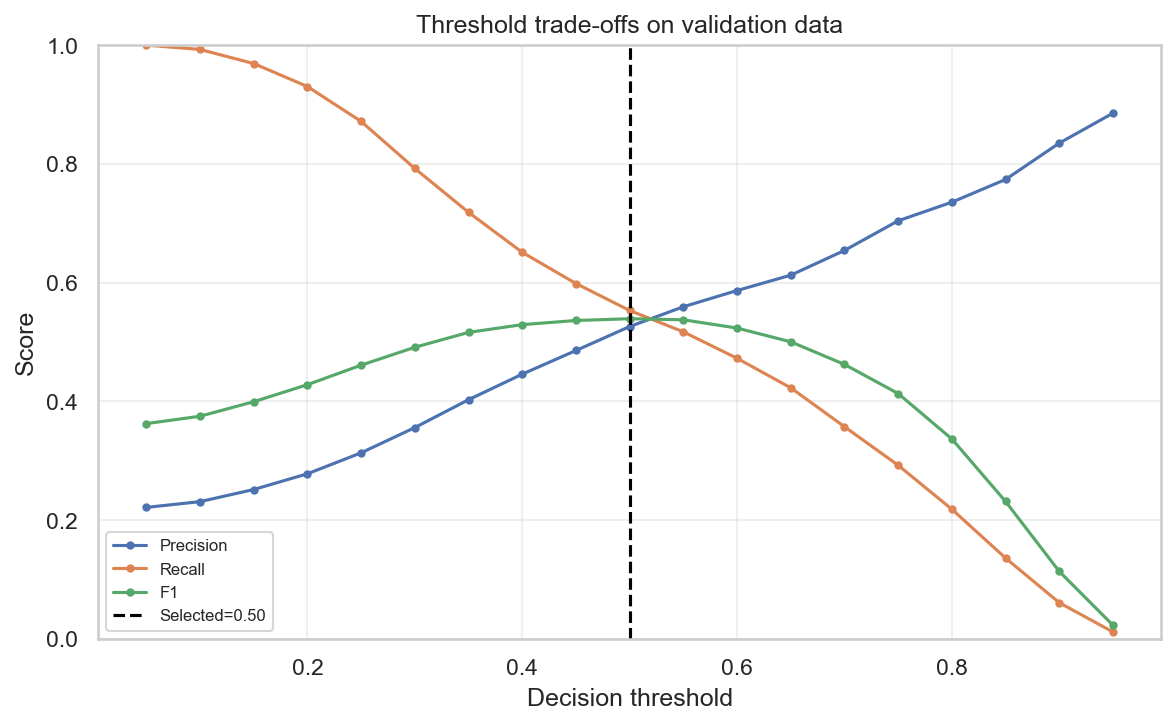

In [30]:
threshold_table = results["threshold_table"]
threshold_view = threshold_table[
    threshold_table["threshold"].between(0.2, 0.7)
][["threshold", "precision", "recall", "f1", "tp", "fp", "fn", "tn"]]
display(threshold_view.round(4).reset_index(drop=True))

display(
    Markdown(
        f"The out-of-fold F1-maximising threshold is **{results['threshold']:.2f}**. "
        f"For transparency, the validation-only F1-maximising threshold was "
        f"**{results['diagnostic_validation_threshold']:.2f}**; it is diagnostic only and did not influence any decision. "
        f"The table is computed from {results['threshold_selection']['n_samples']:,} out-of-fold predictions on the "
        "training split only. Lowering the threshold increases the number of customers flagged as defaulters "
        "(more true positives but also more false positives); raising it does the opposite."
    )
)
display(Image(filename=str(PROJECT_ROOT / "images" / "11_threshold_analysis.png")))

## 17. Final Test Evaluation

Selected pipeline refit on train+validation, evaluated once on the held-out test set.


,selected threshold (0.50),default threshold (0.50)
accuracy,0.7949,0.7949
precision,0.5348,0.5348
recall,0.5558,0.5558
f1,0.5451,0.5451
roc_auc,0.7802,0.7802
pr_auc,0.5598,0.5598
tp,553.0000,553.0000
fp,481.0000,481.0000
fn,442.0000,442.0000
tn,3024.0000,3024.0000


,class,precision,recall,f1-score,support
0,No default,0.8725,0.8628,0.8676,3505.0000
1,Default,0.5348,0.5558,0.5451,995.0000
2,accuracy,0.7949,0.7949,0.7949,0.7949
3,macro avg,0.7036,0.7093,0.7063,4500.0000
4,weighted avg,0.7978,0.7949,0.7963,4500.0000


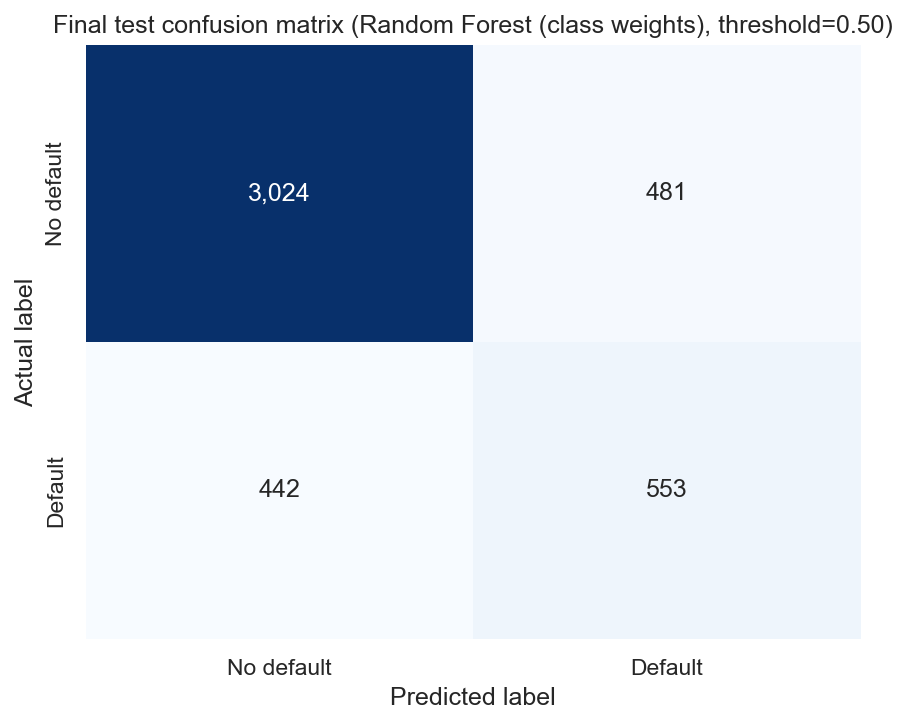

In [31]:
final_metrics = results["final_test_metrics"]
default_metrics = results["final_test_metrics_at_0_5"]
metric_keys = ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "tp", "fp", "fn", "tn"]
metrics_view = pd.DataFrame(
    {
        f"selected threshold ({results['threshold']:.2f})": {
            key: final_metrics[key] for key in metric_keys
        },
        "default threshold (0.50)": {key: default_metrics[key] for key in metric_keys},
    }
)
display(metrics_view.round(4))
display(results["classification_report"].round(4).reset_index(drop=True))
display(Image(filename=str(PROJECT_ROOT / "images" / "10_confusion_matrix.png")))

In [32]:
display(
    Markdown(
        f"On the untouched test set, **{results['selected_model']}** achieves accuracy "
        f"**{final_metrics['accuracy']:.2%}**, precision **{final_metrics['precision']:.2%}**, recall "
        f"**{final_metrics['recall']:.2%}**, F1 **{final_metrics['f1']:.3f}**, ROC-AUC "
        f"**{final_metrics['roc_auc']:.3f}**, and PR-AUC **{final_metrics['pr_auc']:.3f}** at the selected "
        f"threshold of **{results['threshold']:.2f}**. The confusion matrix contains "
        f"{final_metrics['tp']} true positives, {final_metrics['fp']} false positives, "
        f"{final_metrics['fn']} false negatives, and {final_metrics['tn']} true negatives.\n\n"
        "The false-negative count is the number of customers who defaulted but were not flagged; in a lending "
        "context each of these can represent lost principal. The false-positive count is the number of good "
        "customers who would have received unnecessary restrictions. Because these costs are not symmetric, the "
        "out-of-fold F1-maximising threshold is a starting point, not necessarily the final business policy."
    )
)


On the untouched test set, **Random Forest (class weights)** achieves accuracy **79.49%**, precision **53.48%**, recall **55.58%**, F1 **0.545**, ROC-AUC **0.780**, and PR-AUC **0.560** at the selected threshold of **0.50**. The confusion matrix contains 553 true positives, 481 false positives, 442 false negatives, and 3024 true negatives.

The false-negative count is the number of customers who defaulted but were not flagged; in a lending context each of these can represent lost principal. The false-positive count is the number of good customers who would have received unnecessary restrictions. Because these costs are not symmetric, the out-of-fold F1-maximising threshold is a starting point, not necessarily the final business policy.

In [33]:
artifact = load_model_artifact()
new_customers = results["splits"]["test"].drop(columns=[TARGET_COLUMN]).head(5)
predictions = predict_customers(new_customers, artifact)
display(predictions)
print(f"Decision threshold from the saved artefact: {artifact['threshold']:.2f}")

,ID,Default Probability,Prediction
0,1957,0.983875,Default
1,986,0.227467,No Default
2,4244,0.201610,No Default
3,6903,0.178138,No Default
4,21200,0.348617,No Default


Decision threshold from the saved artefact: 0.50


## 18. Feature Importance

Permutation importance on the validation set (primary). Model-based importance shown for comparison.


,feature,importance,importance_std,method,n_repeats
0,PAY_1,0.0692,0.0046,permutation (average_precision),10
1,NUM_SEVERE_DELAY_MONTHS,0.0310,0.0047,permutation (average_precision),10
2,NUM_DELAYED_MONTHS,0.0223,0.0037,permutation (average_precision),10
3,MAX_DELAY_STATUS,0.0165,0.0038,permutation (average_precision),10
4,AVG_DELAY_STATUS,0.0108,0.0032,permutation (average_precision),10
5,PAY_4,0.0035,0.0024,permutation (average_precision),10
6,PAYMENT_TO_BILL_RATIO,0.0034,0.0029,permutation (average_precision),10
7,PAY_AMT3,0.0026,0.0013,permutation (average_precision),10
8,PAY_6,0.0024,0.0014,permutation (average_precision),10
9,PAY_3,0.0020,0.0020,permutation (average_precision),10


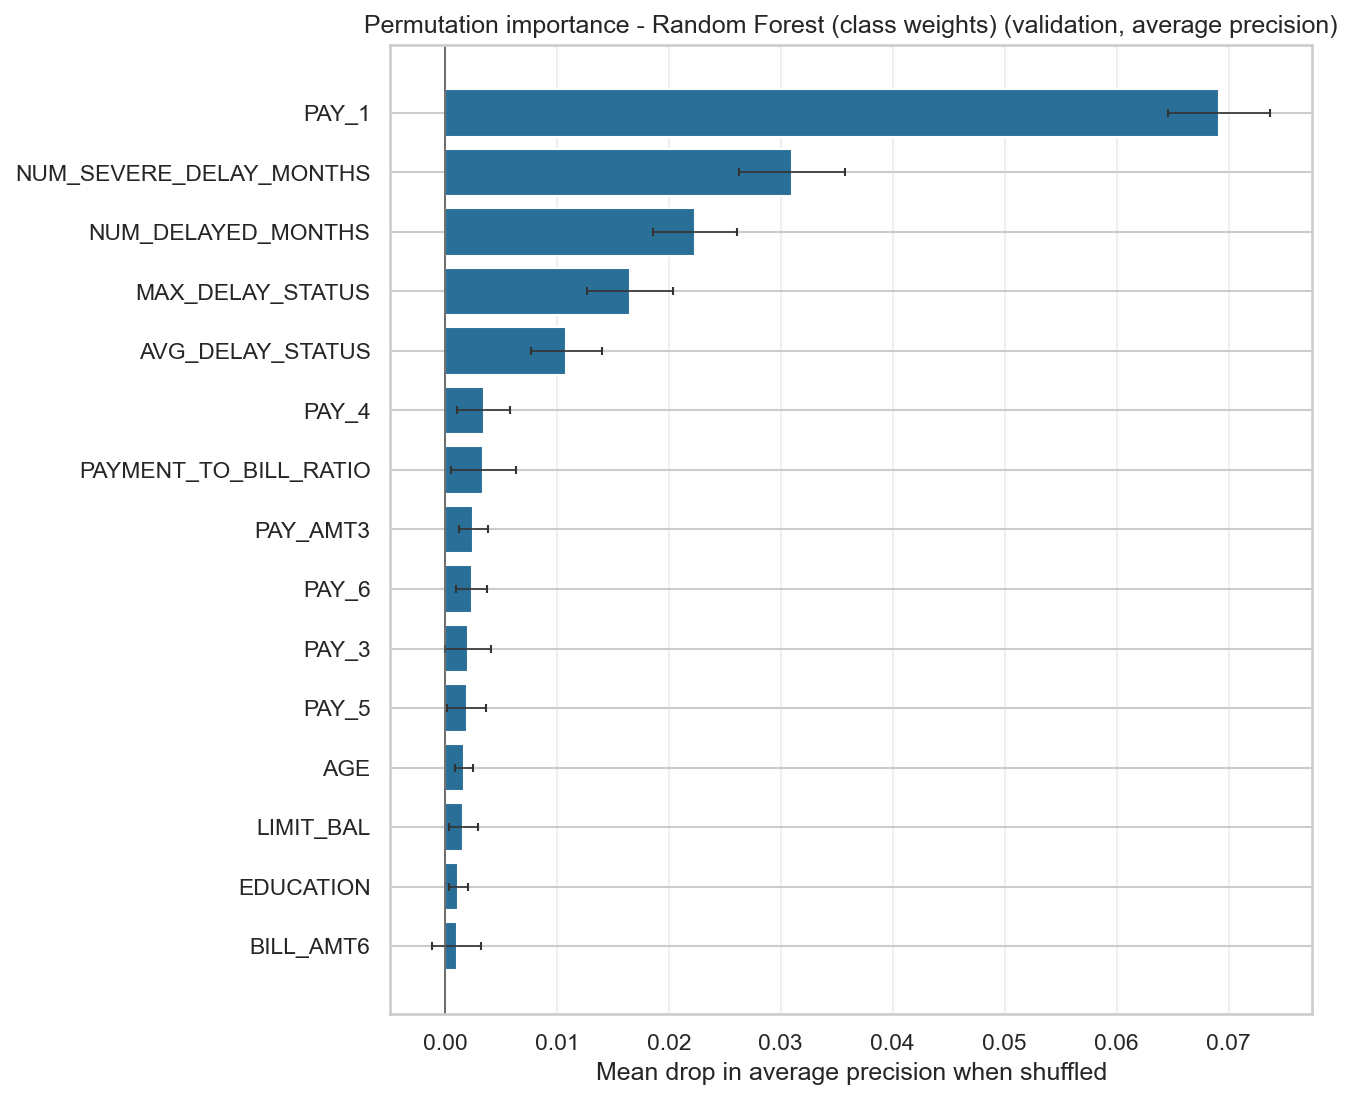

**Model-based importance (impurity or coefficient magnitude; comparison only)**

,feature,importance
0,PAY_1,0.0886
1,NUM_DELAYED_MONTHS,0.0760
2,NUM_SEVERE_DELAY_MONTHS,0.0719
3,MAX_DELAY_STATUS,0.0712
4,AVG_DELAY_STATUS,0.0567
5,UTILIZATION_LAST,0.0354
6,UTILIZATION_AVG,0.0343
7,PAY_TOTAL,0.0318
8,PAYMENT_TO_BILL_RATIO,0.0305
9,PAY_AVG,0.0302


The largest permutation drops come from `PAY_1`, `NUM_SEVERE_DELAY_MONTHS`, `NUM_DELAYED_MONTHS`, `MAX_DELAY_STATUS`, `AVG_DELAY_STATUS`. Repayment behaviour and credit-utilisation features usually dominate; this aligns with the exploratory analysis but should not be interpreted as proof that changing a feature changes a customer's default risk. The comparison table, saved in `reports/feature_importance_model_based.csv`, can rank one-hot encoded or correlated inputs differently.

In [34]:
importance = results["feature_importance"]
display(importance.head(15).round(4).reset_index(drop=True))

importance_image = PROJECT_ROOT / "images" / "12_feature_importance.png"
if importance_image.exists():
    display(Image(filename=str(importance_image)))

model_based = results["model_based_importance"]
if model_based is not None:
    display(Markdown("**Model-based importance (impurity or coefficient magnitude; comparison only)**"))
    display(model_based.head(10).round(4).reset_index(drop=True))

top_five = ", ".join(f"`{feature}`" for feature in importance["feature"].head(5))
display(
    Markdown(
        f"The largest permutation drops come from {top_five}. Repayment behaviour and credit-utilisation "
        "features usually dominate; this aligns with the exploratory analysis but should not be interpreted "
        "as proof that changing a feature changes a customer's default risk. The comparison table, saved in "
        "`reports/feature_importance_model_based.csv`, can rank one-hot encoded or correlated inputs differently."
    )
)


## 19. Subgroup Performance

Metrics by sex, age group, education, and marriage. Small groups are flagged.


,group_attribute,group,n_records,n_defaults,default_rate,precision,recall,f1,fpr,fnr,small_sample
0,SEX,male,1796,430,0.2394,0.5302,0.5721,0.5503,0.1596,0.4279,False
1,SEX,female,2704,565,0.2090,0.5386,0.5434,0.5410,0.1230,0.4566,False
2,AGE_GROUP,29 or younger,1457,321,0.2203,0.5259,0.6012,0.5610,0.1532,0.3988,False
3,AGE_GROUP,30-39,1612,326,0.2022,0.4835,0.4939,0.4886,0.1337,0.5061,False
4,AGE_GROUP,40-49,1009,242,0.2398,0.6009,0.5785,0.5895,0.1213,0.4215,False
5,AGE_GROUP,50-59,360,84,0.2333,0.5542,0.5476,0.5509,0.1341,0.4524,False
6,AGE_GROUP,60+,62,22,0.3548,0.7222,0.5909,0.6500,0.1250,0.4091,True
7,EDUCATION,graduate school,1610,311,0.1932,0.5183,0.5016,0.5098,0.1116,0.4984,False
8,EDUCATION,university,2081,487,0.2340,0.5475,0.5914,0.5686,0.1493,0.4086,False
9,EDUCATION,high school,748,193,0.2580,0.5373,0.5596,0.5482,0.1676,0.4404,False


**Spread across reliable groups (max − min; small groups excluded)**

,precision,recall,f1,fpr,fnr,reliable_groups
SEX,0.0084,0.0287,0.0094,0.0366,0.0287,2.0
AGE_GROUP,0.1174,0.1074,0.1009,0.0319,0.1074,4.0
EDUCATION,0.0293,0.0898,0.0588,0.0559,0.0898,3.0
MARRIAGE,0.0581,0.0020,0.0292,0.0055,0.0020,2.0


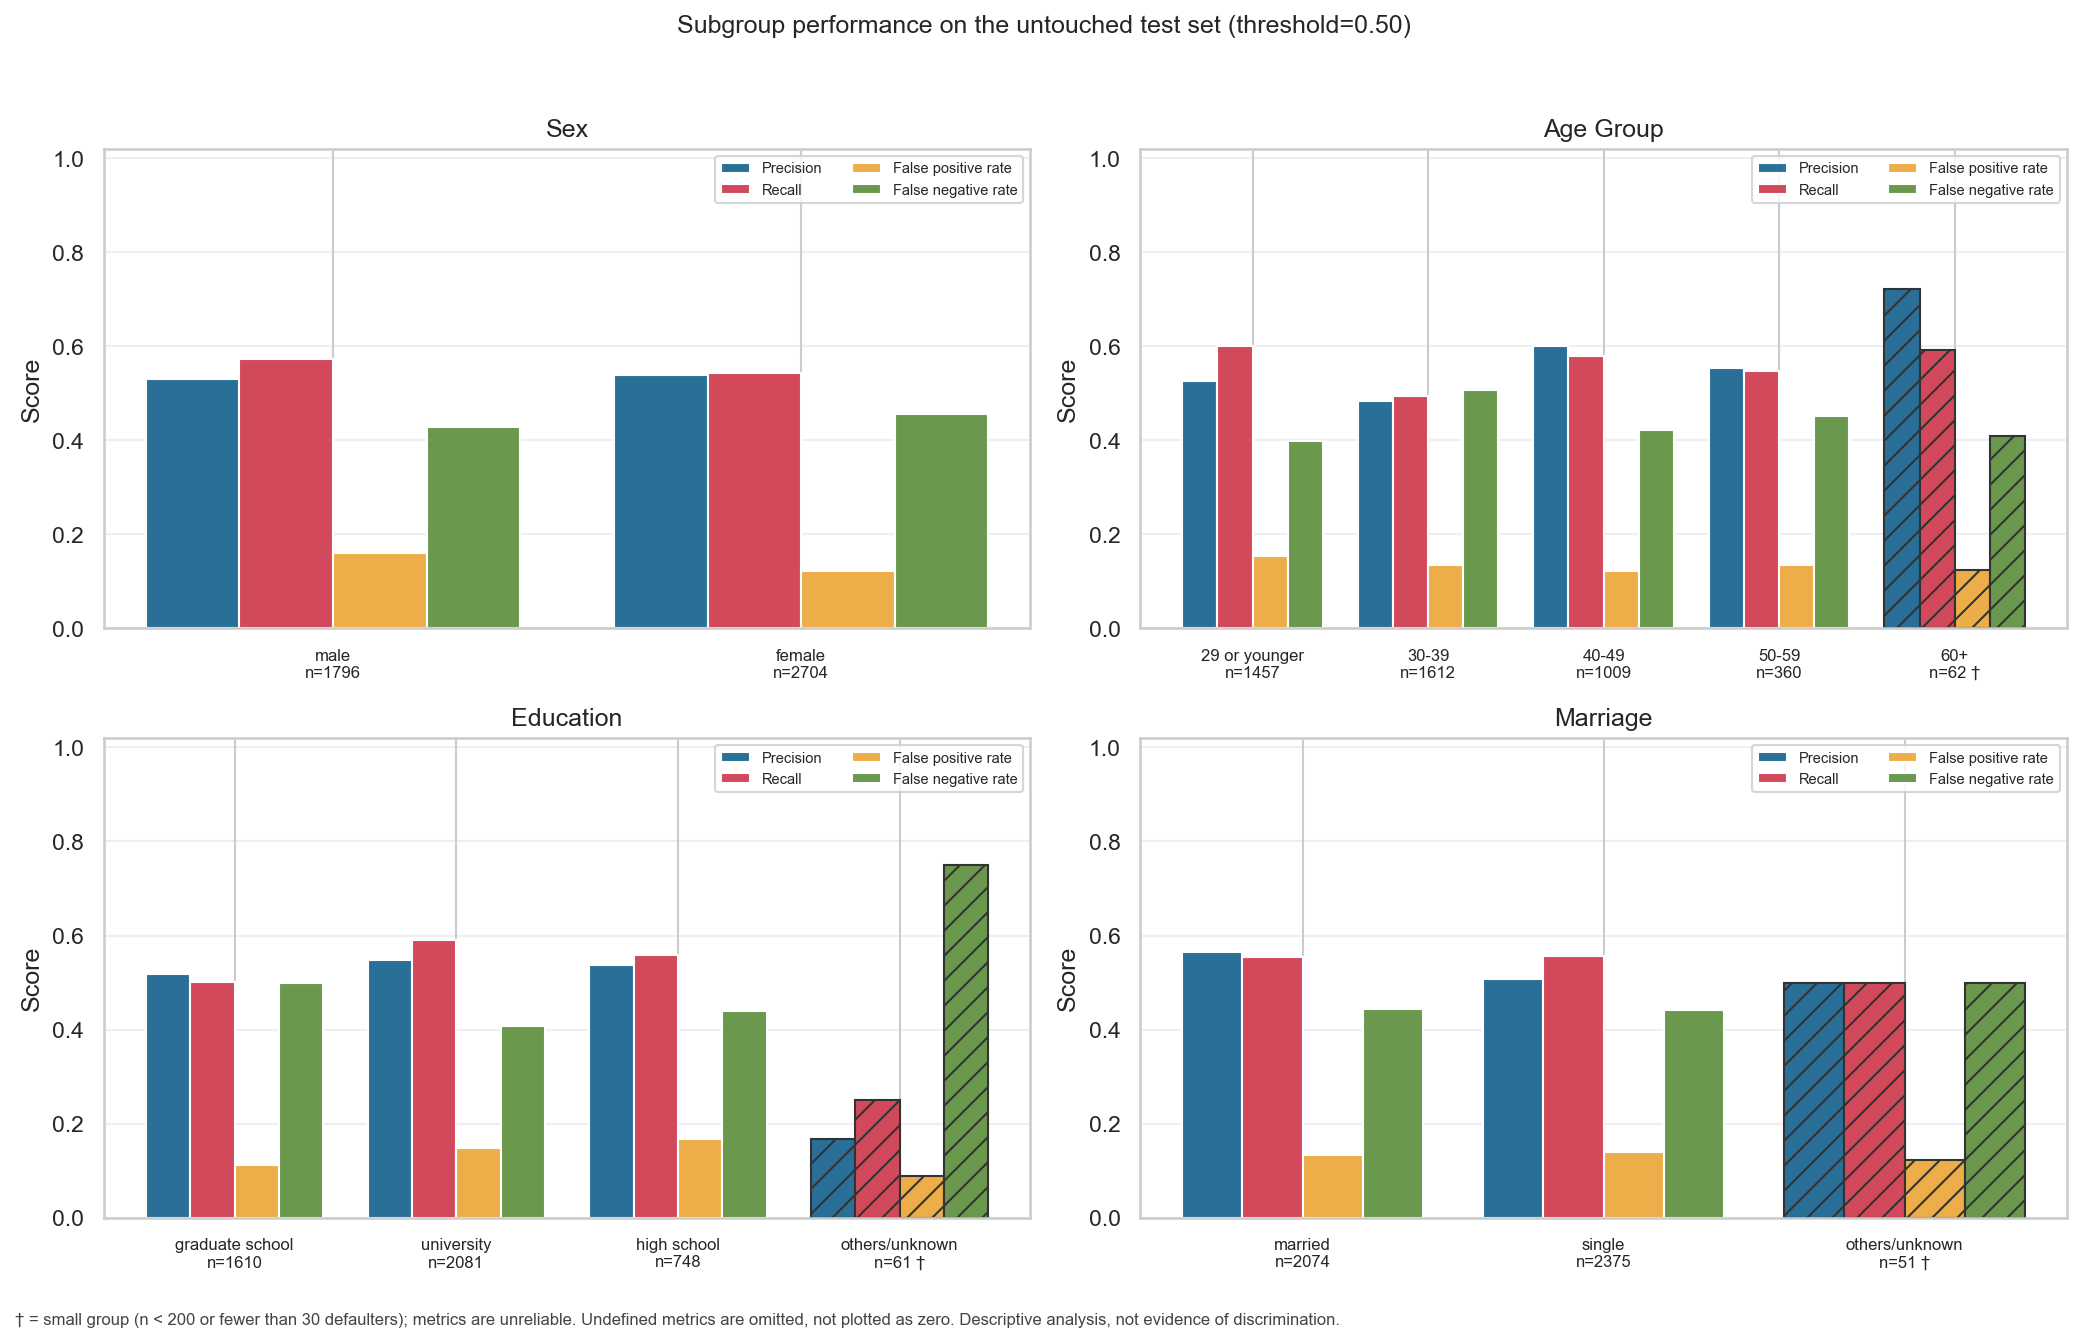

3 of 14 groups are flagged as small, so their metrics should not be treated as reliable. Examples: AGE_GROUP=60+ (n=62); EDUCATION=others/unknown (n=61); MARRIAGE=others/unknown (n=51). Differences among the remaining groups are descriptive; they do not establish discrimination, and no subgroup-specific decision rule was used. A production system would need a broader fairness audit with legally relevant attributes, confidence intervals, and a review of the surrounding decision process.

In [35]:
subgroup = results["subgroup_table"]
report = results["fairness_report"]

view_columns = [
    "group_attribute",
    "group",
    "n_records",
    "n_defaults",
    "default_rate",
    "precision",
    "recall",
    "f1",
    "fpr",
    "fnr",
    "small_sample",
]
display(subgroup[view_columns].round(4).reset_index(drop=True))

display(Markdown("**Spread across reliable groups (max − min; small groups excluded)**"))
display(pd.DataFrame(report["spread_reliable_groups"]).T.round(4))

fairness_image = PROJECT_ROOT / "images" / "13_subgroup_performance.png"
if fairness_image.exists():
    display(Image(filename=str(fairness_image)))

small_examples = "; ".join(
    f"{row['group_attribute']}={row['group']} (n={row['n_records']})"
    for row in report["small_groups"][:6]
)
display(
    Markdown(
        f"{report['n_small_groups']} of {report['n_groups']} groups are flagged as small, so their metrics "
        f"should not be treated as reliable. Examples: {small_examples}. Differences among the remaining groups "
        "are descriptive; they do not establish discrimination, and no subgroup-specific decision rule was used. "
        "A production system would need a broader fairness audit with legally relevant attributes, confidence "
        "intervals, and a review of the surrounding decision process."
    )
)


## 20. Conclusions


In [36]:
policy = results["selection_policy"]
test = results["summary"]["final_test"]["at_selected_threshold"]
display(
    Markdown(
        f"- **Model selection:** {results['selected_model']} was chosen under a documented policy: recall ≥ "
        f"{policy['recall_floor']:.2f} and precision ≥ {policy['precision_floor']:.2f} at threshold "
        f"{policy['reference_threshold']:.2f}, then highest validation PR-AUC among eligible models. "
        f"Policy satisfied: {policy['policy_satisfied']}. No verified financial cost matrix was available, "
        "so this is a modelling objective rather than a cost-optimised decision.\n"
        f"- **Threshold:** {results['threshold']:.2f}, chosen by maximum F1 on out-of-fold predictions from "
        f"the training split only; the validation-only diagnostic was "
        f"{results['diagnostic_validation_threshold']:.2f}. "
        "The test set was not used for selection.\n"
        f"- **Validation PR-AUC:** {results['validation_metrics']['pr_auc']:.4f}; validation recall: "
        f"{results['validation_metrics']['recall']:.4f}.\n"
        f"- **Test performance:** accuracy {test['accuracy']:.4f}, precision {test['precision']:.4f}, "
        f"recall {test['recall']:.4f}, F1 {test['f1']:.4f}, ROC-AUC {test['roc_auc']:.4f}, "
        f"PR-AUC {test['pr_auc']:.4f}.\n"
        "- **Imbalance:** class weighting and SMOTE were compared against unweighted baselines; they change the "
        "precision/recall balance but do not automatically improve ranking quality.\n"
        "- **Feature importance:** permutation importance on validation is the primary explanation; impurity "
        "importance is reported separately because correlated and derived features can share credit. Neither "
        "is causal.\n"
        "- **Subgroup performance:** subgroup metrics are reported with sample sizes and small-group warnings. "
        "This is an exploratory assessment, not a fairness audit.\n"
        "- **Reproducibility:** fixed random state, stratified split before preprocessing, all learned transforms "
        "fitted on training data, out-of-fold threshold selection, and reports written by code.\n"
        "- **Practical interpretation:** the model ranks risk better than chance, but its precision at the chosen "
        "threshold means many flagged customers would not have defaulted. Deployment should set the threshold "
        "from the actual dollar cost of false negatives versus false positives."
    )
)


- **Model selection:** Random Forest (class weights) was chosen under a documented policy: recall ≥ 0.55 and precision ≥ 0.50 at threshold 0.50, then highest validation PR-AUC among eligible models. Policy satisfied: True. No verified financial cost matrix was available, so this is a modelling objective rather than a cost-optimised decision.
- **Threshold:** 0.50, chosen by maximum F1 on out-of-fold predictions from the training split only; the validation-only diagnostic was 0.50. The test set was not used for selection.
- **Validation PR-AUC:** 0.5623; validation recall: 0.5578.
- **Test performance:** accuracy 0.7949, precision 0.5348, recall 0.5558, F1 0.5451, ROC-AUC 0.7802, PR-AUC 0.5598.
- **Imbalance:** class weighting and SMOTE were compared against unweighted baselines; they change the precision/recall balance but do not automatically improve ranking quality.
- **Feature importance:** permutation importance on validation is the primary explanation; impurity importance is reported separately because correlated and derived features can share credit. Neither is causal.
- **Subgroup performance:** subgroup metrics are reported with sample sizes and small-group warnings. This is an exploratory assessment, not a fairness audit.
- **Reproducibility:** fixed random state, stratified split before preprocessing, all learned transforms fitted on training data, out-of-fold threshold selection, and reports written by code.
- **Practical interpretation:** the model ranks risk better than chance, but its precision at the chosen threshold means many flagged customers would not have defaulted. Deployment should set the threshold from the actual dollar cost of false negatives versus false positives.

## 21. Limitations

- Data is from 2005 Taiwan; behaviour and products have changed.
- Split is random, not out-of-time.
- Feature importance is associative, not causal.
- Threshold maximises F1; real lending needs a cost matrix.
- Subgroup analysis is exploratory, not a fairness audit.
- Probabilities are not separately calibrated.
- No income, employment, or bureau scores in the feature set.
- Single stratified split; no confidence intervals on test metrics.
